<a href="https://colab.research.google.com/github/SenudaR20/visual-anomaly-detection/blob/main/algorithms/VAE/VAE_Leather.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import Libraries

In [ ]:
# Algorithm 2: Variational Autoencoder (VAE)
# Dataset: Bottle (MVTec AD)

import os, random, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image

from scipy.ndimage import gaussian_filter
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
from tensorflow.keras import layers, Model

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


In [ ]:
# connecting google Drive

from google .colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
CATEGORY = "Leather"

DATA_ROOT = Path(f"/content/drive/MyDrive/MvTech_Dataset/leather")
TRAIN_DIR = DATA_ROOT / "train" / "good"
TEST_DIR  = DATA_ROOT / "test"
MASK_DIR  = DATA_ROOT / "ground_truth"

assert TRAIN_DIR.exists(), f"Training folder not found: {TRAIN_DIR}"
assert TEST_DIR.exists(),  f"Test folder not found: {TEST_DIR}"
print("Dataset found:", DATA_ROOT)

Dataset found: /content/drive/MyDrive/MvTech_Dataset/leather


In [ ]:

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp"}

def get_images(folder):
    folder = Path(folder)

    if not folder.exists():
        return []

    return sorted([
        path
        for path in folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ])


# Normal images for training
train_images = get_images(TRAIN_DIR)

# All test images, including normal and defective examples
test_images = []

for folder in sorted(TEST_DIR.iterdir()):
    if folder.is_dir():
        test_images.extend(get_images(folder))

print("Normal training images:", len(train_images))
print("Total test images:", len(test_images))

print("\nTest categories:")
for folder in sorted(TEST_DIR.iterdir()):
    if folder.is_dir():
        print(f"{folder.name}: {len(get_images(folder))}")


Normal training images: 245
Total test images: 124

Test categories:
color: 19
cut: 19
fold: 17
glue: 19
good: 32
poke: 18


Preprocess the images

In [ ]:

IMG_HEIGHT = 128
IMG_WIDTH = 128
CHANNELS = 3

def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")

    image = image.resize(
        (IMG_WIDTH, IMG_HEIGHT),
        Image.Resampling.BILINEAR
    )

    return np.asarray(
        image,
        dtype=np.float32
    ) / 255.0


X_train = np.stack([
    preprocess_image(path)
    for path in train_images
])

print("Training array shape:", X_train.shape)
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())


Training array shape: (245, 128, 128, 3)
Minimum pixel value: 0.15294118
Maximum pixel value: 0.6627451


Split the normal images into training and validation sets

In [ ]:

X_train_final, X_val = train_test_split(
    X_train,
    test_size=0.15,
    random_state=SEED,
    shuffle=True
)

print("Training images:", X_train_final.shape)
print("Validation images:", X_val.shape)


Training images: (208, 128, 128, 3)
Validation images: (37, 128, 128, 3)


Build the VAE encoder

In [ ]:
LATENT_DIM = 64

encoder_inputs = layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS), name="encoder_input")
x = encoder_inputs


for f in [32, 64, 128, 128]:
    x = layers.Conv2D(f, 3, strides=2, padding="same", activation="relu")(x)

x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)

z_mean = layers.Dense(LATENT_DIM, name="z_mean")(x)
z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(x)

encoder = Model(encoder_inputs, [z_mean, z_log_var], name="VAE_encoder")
encoder.summary()

Model: "VAE_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │        896 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │     18,496 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 16, 16,    │     73,856 │ conv2d_1[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 8, 8, 128) │    147,584 │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 8192)      │          0 │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  2,097,408 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 64)        │     16,448 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 64)        │     16,448 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,371,136 (9.05 MB)

 Trainable params: 2,371,136 (9.05 MB)

 Non-trainable params: 0 (0.00 B)

Implement the reparameterization trick

In [ ]:
class Sampling(layers.Layer):
  """Sampling a latent vector using the reparameterization trick."""

  def call(self, inputs):
        z_mean, z_log_var = inputs

        epsilon = tf.random.normal(shape=tf.shape(z_mean))

        z = z_mean + tf.exp(0.5 * z_log_var) * epsilon

        return z


sampling = Sampling(name="sampling")
z = sampling([z_mean, z_log_var])

print("Latent mean shape:", z_mean.shape)
print("Latent log-variance shape:", z_log_var.shape)
print("Sampled latent shape:", z.shape)


Latent mean shape: (None, 64)
Latent log-variance shape: (None, 64)
Sampled latent shape: (None, 64)


Build the VAE decoder

In [ ]:
decoder_inputs = layers.Input(shape=(LATENT_DIM,), name="decoder_input")


x = layers.Dense(8 * 8 * 128)(decoder_inputs)
x = layers.Reshape((8, 8, 128))(x)

for f in [128, 128, 64, 32]:
    x = layers.Conv2DTranspose(f, 3, strides=2, padding="same", activation="relu")(x)

decoder_outputs = layers.Conv2D(
    CHANNELS, 3, padding="same", activation="sigmoid", name="reconstructed_image"
)(x)

decoder = Model(decoder_inputs, decoder_outputs, name="VAE_decoder")
decoder.summary()

Model: "VAE_decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8192)           │       532,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 128)    │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 128)    │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 64, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 128, 128, 32)   │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_image (Conv2D)    │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 920,771 (3.51 MB)

 Trainable params: 920,771 (3.51 MB)

 Non-trainable params: 0 (0.00 B)

Combine the encoder and decoder

In [ ]:

# Connect the full VAE
vae_outputs = decoder(z)

vae = Model(
    encoder_inputs,
    vae_outputs,
    name="Bottle_VAE"
)

print("VAE constructed successfully.")
print("Input shape:", vae.input_shape)
print("Output shape:", vae.output_shape)


VAE constructed successfully.
Input shape: (None, 128, 128, 3)
Output shape: (None, 128, 128, 3)


Implement the VAE loss function


In [ ]:

BETA_MAX = 0.01
WARMUP_EPOCHS = 40
beta = tf.Variable(0.0, trainable=False, dtype=tf.float32)

Set up the training datasets


In [ ]:
BATCH_SIZE = 16


def augment(img):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    k = tf.random.uniform([], 0, 4, dtype=tf.int32)
    return tf.image.rot90(img, k)

train_ds = (
    tf.data.Dataset.from_tensor_slices(X_train_final)
    .shuffle(len(X_train_final), seed=SEED)
    .map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices(X_val)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

steps_per_epoch = int(np.ceil(len(X_train_final) / BATCH_SIZE))
print("Steps per epoch:", steps_per_epoch)

Steps per epoch: 13


Configure the optimizer and training metrics

In [ ]:

LEARNING_RATE = 5e-4
optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0)

train_loss_metric = tf.keras.metrics.Mean(name="train_loss")
train_reconstruction_metric = tf.keras.metrics.Mean(name="train_reconstruction_loss")
train_kl_metric = tf.keras.metrics.Mean(name="train_kl_loss")
val_loss_metric = tf.keras.metrics.Mean(name="val_loss")
val_reconstruction_metric = tf.keras.metrics.Mean(name="val_reconstruction_loss")
val_kl_metric = tf.keras.metrics.Mean(name="val_kl_loss")
print("Optimizer and metrics configured.")

Optimizer and metrics configured.


Create the custom training loop

In [ ]:
def kl_divergence(mean, log_var):
    return -0.5 * tf.reduce_sum(1.0 + log_var - tf.square(mean) - tf.exp(log_var), axis=1)

@tf.function
def train_step(images):
    with tf.GradientTape() as tape:
        mean, log_var = encoder(images, training=True)
        sampled_z = sampling([mean, log_var])
        reconstructed = decoder(sampled_z, training=True)

        reconstruction_loss = tf.reduce_sum(tf.square(images - reconstructed), axis=[1, 2, 3])
        kl_loss = kl_divergence(mean, log_var)

        # beta-weighted VAE loss
        total_loss = tf.reduce_mean(reconstruction_loss + beta * kl_loss)

    variables = encoder.trainable_variables + decoder.trainable_variables
    grads = tape.gradient(total_loss, variables)
    optimizer.apply_gradients(zip(grads, variables))
    return total_loss, tf.reduce_mean(reconstruction_loss), tf.reduce_mean(kl_loss)


@tf.function
def validation_step(images):
    mean, log_var = encoder(images, training=False)
    reconstructed = decoder(mean, training=False)   # deterministic: decode the mean

    reconstruction_loss = tf.reduce_sum(tf.square(images - reconstructed), axis=[1, 2, 3])
    kl_loss = kl_divergence(mean, log_var)
    total_loss = tf.reduce_mean(reconstruction_loss + beta * kl_loss)
    return total_loss, tf.reduce_mean(reconstruction_loss), tf.reduce_mean(kl_loss)

print("Training and validation steps defined.")

Training and validation steps defined.


Run one test batch before full training

In [ ]:

for batch in train_ds.take(1):
    total, reconstruction, kl = train_step(batch)

    print("Total loss:", float(total))
    print("Reconstruction loss:", float(reconstruction))
    print("KL-divergence loss:", float(kl))


Total loss: 2417.796630859375
Reconstruction loss: 2417.796630859375
KL-divergence loss: 0.0032363347709178925


Setup model saving and training history

In [ ]:
OUTPUT_DIR = Path(f"/content/drive/MyDrive/VAE_Leather_Results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


EPOCHS = 300
PATIENCE = 40

history = {k: [] for k in [
    "train_loss", "train_reconstruction_loss", "train_kl_loss",
    "val_loss", "val_reconstruction_loss", "val_kl_loss"]}

best_val_recon = float("inf")
best_epoch = 0
epochs_without_improvement = 0
print("Results directory:", OUTPUT_DIR)

Results directory: /content/drive/MyDrive/VAE_Leather_Results


Train the VAE

In [ ]:
for epoch in range(EPOCHS):
    beta.assign(BETA_MAX * min(1.0, (epoch + 1) / WARMUP_EPOCHS))   # KL warm-up

    for m in [train_loss_metric, train_reconstruction_metric, train_kl_metric,
              val_loss_metric, val_reconstruction_metric, val_kl_metric]:
        m.reset_state()

    for batch in train_ds:
        total, recon, kl = train_step(batch)
        train_loss_metric.update_state(total)
        train_reconstruction_metric.update_state(recon)
        train_kl_metric.update_state(kl)

    for batch in val_ds:
        total, recon, kl = validation_step(batch)
        val_loss_metric.update_state(total)
        val_reconstruction_metric.update_state(recon)
        val_kl_metric.update_state(kl)

    train_loss = float(train_loss_metric.result()); train_recon = float(train_reconstruction_metric.result())
    train_kl = float(train_kl_metric.result());     val_loss = float(val_loss_metric.result())
    val_recon = float(val_reconstruction_metric.result()); val_kl = float(val_kl_metric.result())

    for k, v in zip(history.keys(), [train_loss, train_recon, train_kl, val_loss, val_recon, val_kl]):
        history[k].append(v)

    msg = (f"Epoch {epoch + 1:03d}/{EPOCHS} | beta {float(beta):.4f} | "
           f"Train recon {train_recon:.2f}, KL {train_kl:.2f} | "
           f"Val recon {val_recon:.2f}, KL {val_kl:.2f}")

    # Collapse check every 10 epochs: how many latent dimensions actually carry information?
    if (epoch + 1) % 10 == 0:
        vm, _ = encoder.predict(X_val, batch_size=32, verbose=0)
        active = int(np.sum(np.var(vm, axis=0) > 0.01))
        msg += f" | active latent dims {active}/{LATENT_DIM}"
    print(msg)

    if val_recon < best_val_recon:
        best_val_recon = val_recon
        best_epoch = epoch + 1
        epochs_without_improvement = 0
        vae.save_weights(str(OUTPUT_DIR / "best_vae.weights.h5"))
    else:
        epochs_without_improvement += 1

    # only allow early stopping once beta has fully ramped up
    if epoch + 1 > WARMUP_EPOCHS and epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch + 1}. Best epoch: {best_epoch}")
        break

print("\nTraining finished.")
print("Best epoch:", best_epoch)
print("Best validation reconstruction loss:", round(best_val_recon, 4))

Epoch 001/300 | beta 0.0003 | Train recon 2430.08, KL 248669.09 | Val recon 430.46, KL 336474.91
Epoch 002/300 | beta 0.0005 | Train recon 889.79, KL 33156.49 | Val recon 353.72, KL 645.38
Epoch 003/300 | beta 0.0008 | Train recon 287.11, KL 247.52 | Val recon 128.55, KL 130.51
Epoch 004/300 | beta 0.0010 | Train recon 164.51, KL 86.87 | Val recon 137.74, KL 96.42
Epoch 005/300 | beta 0.0012 | Train recon 197.17, KL 70.35 | Val recon 330.00, KL 99.64
Epoch 006/300 | beta 0.0015 | Train recon 221.52, KL 69.65 | Val recon 193.34, KL 96.98
Epoch 007/300 | beta 0.0018 | Train recon 128.69, KL 80.17 | Val recon 100.57, KL 81.19
Epoch 008/300 | beta 0.0020 | Train recon 88.43, KL 95.86 | Val recon 83.80, KL 119.71
Epoch 009/300 | beta 0.0022 | Train recon 91.19, KL 109.01 | Val recon 87.63, KL 103.76
Epoch 010/300 | beta 0.0025 | Train recon 81.16, KL 115.95 | Val recon 94.71, KL 115.29 | active latent dims 11/64
Epoch 011/300 | beta 0.0027 | Train recon 97.22, KL 148.81 | Val recon 72.02, K

Plot the training and validation loss


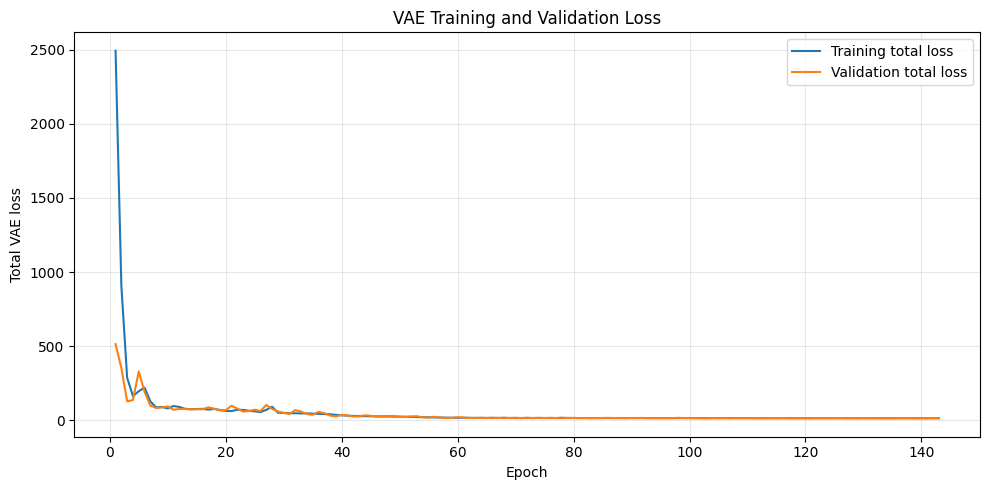

In [ ]:

epochs_completed = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_completed,
    history["train_loss"],
    label="Training total loss"
)

plt.plot(
    epochs_completed,
    history["val_loss"],
    label="Validation total loss"
)

plt.xlabel("Epoch")
plt.ylabel("Total VAE loss")
plt.title("VAE Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Examine the two loss components

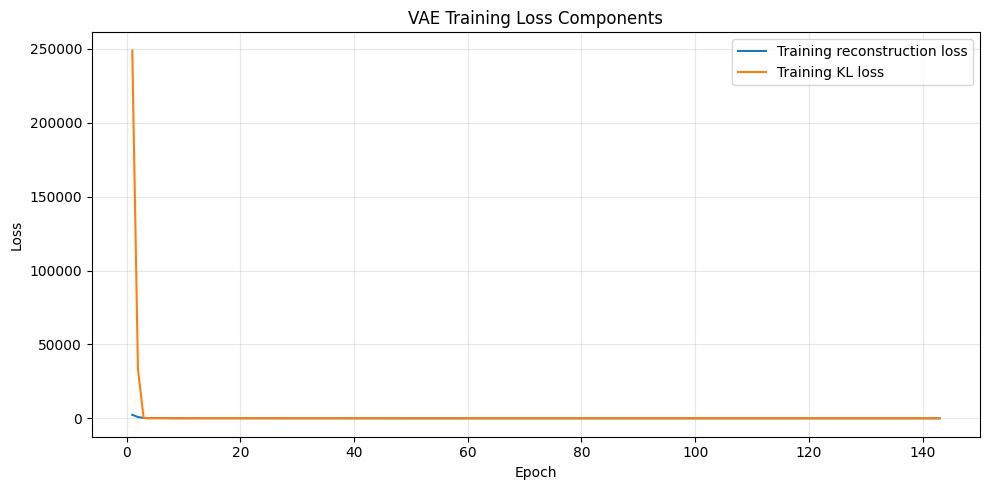

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_completed,
    history["train_reconstruction_loss"],
    label="Training reconstruction loss"
)

plt.plot(
    epochs_completed,
    history["train_kl_loss"],
    label="Training KL loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss Components")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Restore the best checkpoint

In [ ]:

vae.load_weights(str(OUTPUT_DIR / "best_vae.weights.h5"))
print("Best VAE checkpoint loaded.")
print("Best epoch:", best_epoch)
print("Best validation reconstruction loss:", best_val_recon)

Best VAE checkpoint loaded.
Best epoch: 103
Best validation reconstruction loss: 13.456684112548828


Visualize VAE reconstructions

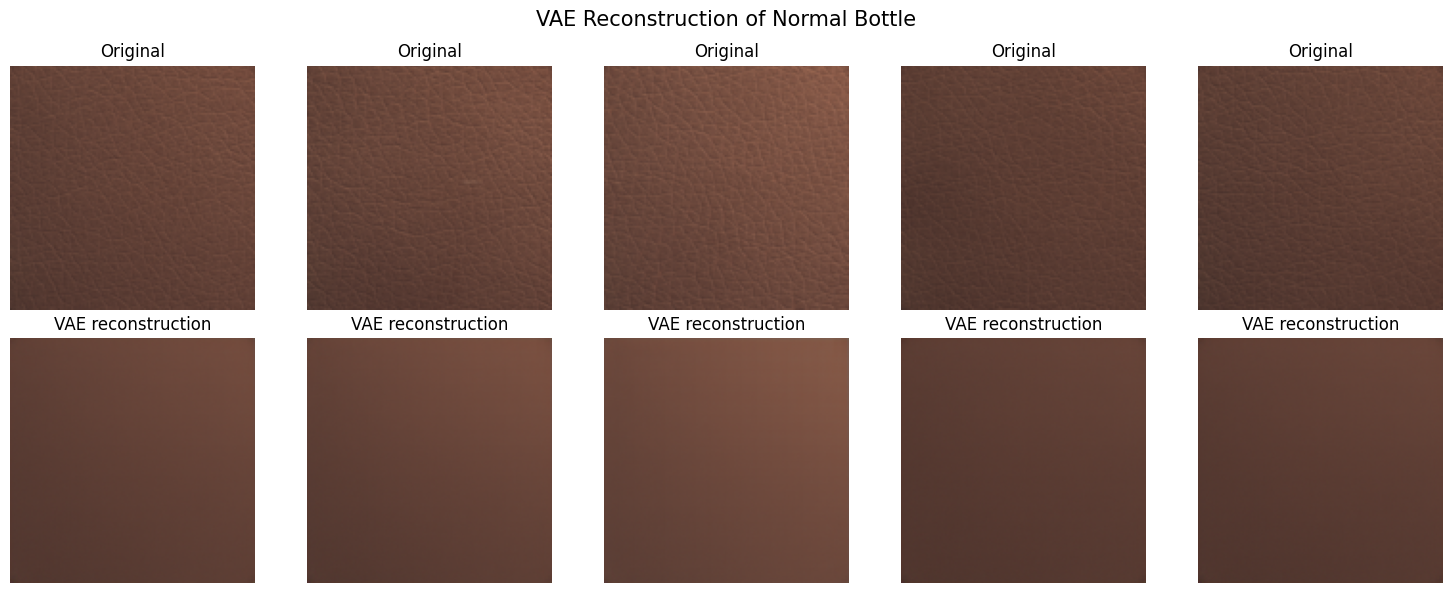

Mean absolute reconstruction error: 0.012304755859076977
Mean latent variance: 0.24878183007240295
Reconstruction pixel std: 0.0779


In [ ]:

n = min(5, len(X_val))
sample_images = X_val[:n]

# Obtain latent means and decode them
sample_means, sample_log_vars = encoder.predict(
    sample_images,
    verbose=0
)

reconstructed_images = decoder.predict(
    sample_means,
    verbose=0
)

plt.figure(figsize=(15, 6))

for i in range(n):
    plt.subplot(2, n, i + 1)
    plt.imshow(sample_images[i])
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, n, n + i + 1)
    plt.imshow(np.clip(reconstructed_images[i], 0, 1))
    plt.title("VAE reconstruction")
    plt.axis("off")

plt.suptitle("VAE Reconstruction of Normal Bottle", fontsize=15)
plt.tight_layout()
plt.show()

print("Mean absolute reconstruction error:",
      float(np.mean(np.abs(sample_images - reconstructed_images))))

print("Mean latent variance:",
      float(np.mean(np.exp(sample_log_vars))))

# Collapse check: a real reconstruction has visible variation. A flat gray image has std ~ 0.
recon_std = float(np.std(reconstructed_images))
print("Reconstruction pixel std:", round(recon_std, 4))
if recon_std < 0.02:
    print("WARNING: reconstructions look collapsed (flat). Lower BETA_MAX, train longer, or check the layers.")



Plot the loss curves on a logarithmic scale

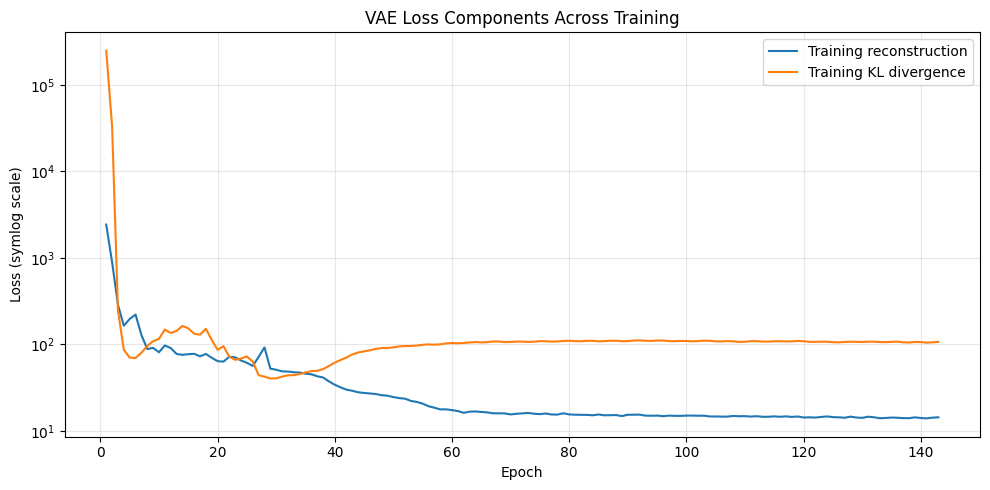

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_completed,
    history["train_reconstruction_loss"],
    label="Training reconstruction"
)

plt.plot(
    epochs_completed,
    history["train_kl_loss"],
    label="Training KL divergence"
)

plt.yscale("symlog", linthresh=1)
plt.xlabel("Epoch")
plt.ylabel("Loss (symlog scale)")
plt.title("VAE Loss Components Across Training")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Load the test images

In [ ]:

# Label normal images as 0 and defective images as 1
test_labels = np.array([
    0 if path.parent.name == "good" else 1
    for path in test_images
])

test_categories = np.array([
    path.parent.name for path in test_images
])

# Preprocess all test images
X_test = np.stack([
    preprocess_image(path)
    for path in test_images
])

print("Test array shape:", X_test.shape)
print("Normal images:", int(np.sum(test_labels == 0)))
print("Defective images:", int(np.sum(test_labels == 1)))


Test array shape: (124, 128, 128, 3)
Normal images: 32
Defective images: 92


Calculate VAE anomaly scores

In [ ]:
test_means, test_log_vars = encoder.predict(X_test, batch_size=16, verbose=1)
X_reconstructed = decoder.predict(test_means, batch_size=16, verbose=1)

# pixel-level mean absolute error maps
test_error_maps = np.mean(np.abs(X_test - X_reconstructed), axis=-1)

# FIX 8: score = max of the Gaussian-smoothed error map (small defects are no longer averaged away)
def smooth_max_score(error_maps, sigma=3):
    return np.array([gaussian_filter(m, sigma=sigma).max() for m in error_maps])

mean_scores = np.mean(test_error_maps, axis=(1, 2))            # old score, for comparison
image_anomaly_scores = smooth_max_score(test_error_maps)        # new score

print("ROC-AUC with old mean-error score    :", round(roc_auc_score(test_labels, mean_scores), 4))
print("ROC-AUC with smoothed-max score (new):", round(roc_auc_score(test_labels, image_anomaly_scores), 4))
print("Mean normal score   :", float(image_anomaly_scores[test_labels == 0].mean()))
print("Mean defective score:", float(image_anomaly_scores[test_labels == 1].mean()))

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 215ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 750ms/step
ROC-AUC with old mean-error score    : 0.6498
ROC-AUC with smoothed-max score (new): 0.9314
Mean normal score   : 0.03350157290697098
Mean defective score: 0.08640295267105103


Evaluate image-level ROC-AUC

VAE image-level ROC-AUC: 0.9314


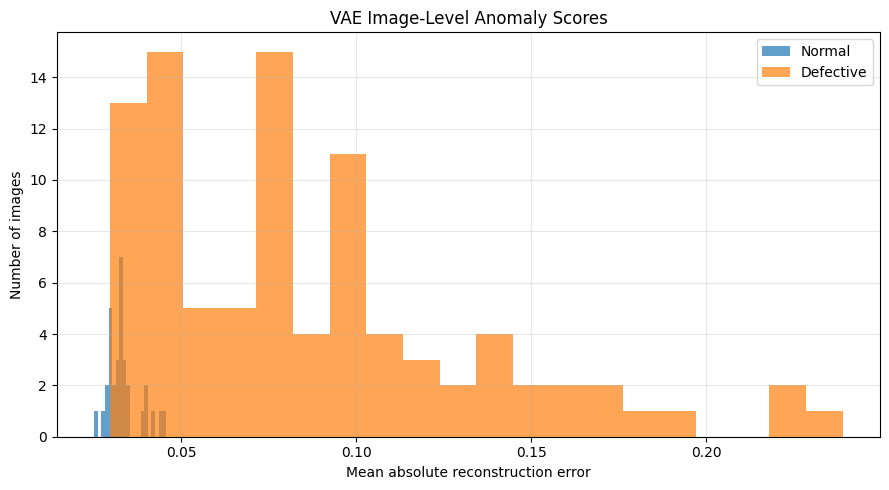

In [ ]:

from sklearn.metrics import roc_auc_score

if len(np.unique(test_labels)) == 2:
    image_roc_auc = roc_auc_score(
        test_labels,
        image_anomaly_scores
    )
    print(f"VAE image-level ROC-AUC: {image_roc_auc:.4f}")
else:
    print("ROC-AUC requires both normal and defective test images.")

plt.figure(figsize=(9, 5))

plt.hist(
    image_anomaly_scores[test_labels == 0],
    bins=20,
    alpha=0.7,
    label="Normal"
)

plt.hist(
    image_anomaly_scores[test_labels == 1],
    bins=20,
    alpha=0.7,
    label="Defective"
)

plt.xlabel("Mean absolute reconstruction error")
plt.ylabel("Number of images")
plt.title("VAE Image-Level Anomaly Scores")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Select a threshold using normal validation images

In [ ]:
val_means, val_log_vars = encoder.predict(X_val, batch_size=16, verbose=0)
val_reconstructions = decoder.predict(val_means, batch_size=16, verbose=0)

val_error_maps = np.mean(np.abs(X_val - val_reconstructions), axis=-1)
val_anomaly_scores = smooth_max_score(val_error_maps)       # same scoring function as the test set

THRESHOLD_PERCENTILE = 95
anomaly_threshold = np.percentile(val_anomaly_scores, THRESHOLD_PERCENTILE)
print("VAE anomaly threshold:", round(float(anomaly_threshold), 6))

VAE anomaly threshold: 0.033117


Evaluate classification performance

In [ ]:



vae_predictions = (
    image_anomaly_scores > anomaly_threshold
).astype(int)

print("VAE confusion matrix:")
print(confusion_matrix(test_labels, vae_predictions))

print("\nVAE classification report:")
print(classification_report(
    test_labels,
    vae_predictions,
    target_names=["Normal", "Defective"],
    zero_division=0
))


VAE confusion matrix:
[[17 15]
 [ 6 86]]

VAE classification report:
              precision    recall  f1-score   support

      Normal       0.74      0.53      0.62        32
   Defective       0.85      0.93      0.89        92

    accuracy                           0.83       124
   macro avg       0.80      0.73      0.75       124
weighted avg       0.82      0.83      0.82       124



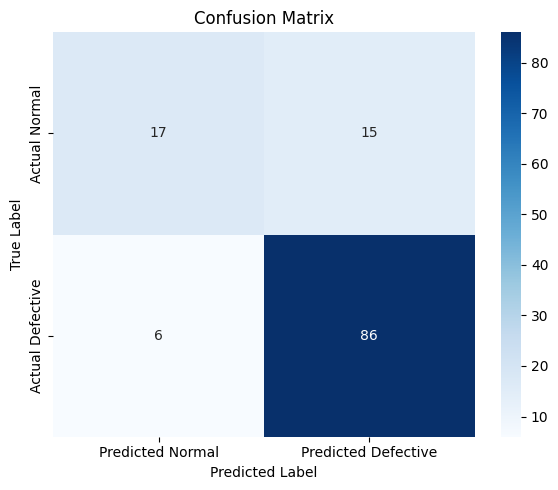

In [ ]:
import seaborn as sns
# Compute confusion matrix
cm = confusion_matrix(test_labels, vae_predictions)

# Plot
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Normal", "Predicted Defective"],
    yticklabels=["Actual Normal", "Actual Defective"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

Save Results

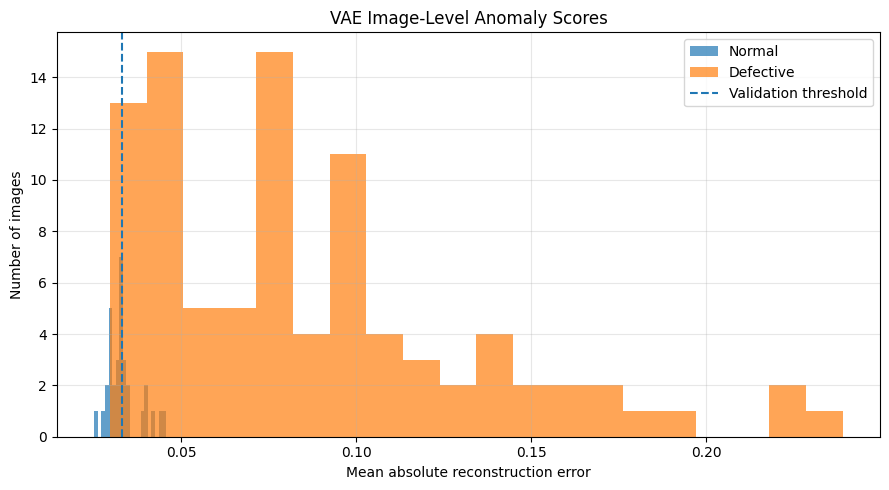

VAE results saved successfully to:
/content/drive/MyDrive/VAE_Leather_Results

Saved files:
- best_vae.weights.h5
- vae_anomaly_score_histogram.png
- vae_classification_report.csv
- vae_confusion_matrix.csv
- vae_metrics.json
- vae_test_predictions.csv
- vae_training_history.csv


In [ ]:

import json
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save image-level predictions and anomaly scores
predictions_df = pd.DataFrame({
    "image_path": [str(p) for p in test_images],
    "category": test_categories,
    "true_label": test_labels,
    "anomaly_score": image_anomaly_scores,
    "predicted_label": vae_predictions
})

predictions_df.to_csv(
    OUTPUT_DIR / "vae_test_predictions.csv",
    index=False
)

# 2. Save confusion matrix
cm = confusion_matrix(test_labels, vae_predictions)

cm_df = pd.DataFrame(
    cm,
    index=["Actual_Normal", "Actual_Defective"],
    columns=["Predicted_Normal", "Predicted_Defective"]
)

cm_df.to_csv(OUTPUT_DIR / "vae_confusion_matrix.csv")

# 3. Save classification report
report = classification_report(
    test_labels,
    vae_predictions,
    target_names=["Normal", "Defective"],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    OUTPUT_DIR / "vae_classification_report.csv"
)

# 4. Save training history
pd.DataFrame(history).to_csv(
    OUTPUT_DIR / "vae_training_history.csv",
    index_label="epoch"
)

# 5. Save summary metrics and threshold
metrics = {
    "model": "Convolutional beta-VAE (no BN)",
    "dataset": f"MVTec AD {CATEGORY}",
    "image_height": IMG_HEIGHT,
    "image_width": IMG_WIDTH,
    "channels": CHANNELS,
    "latent_dim": LATENT_DIM,
    "best_epoch": int(best_epoch),
    "best_validation_recon_loss": float(best_val_recon),
    "threshold_percentile": THRESHOLD_PERCENTILE,
    "anomaly_threshold": float(anomaly_threshold),
    "image_level_roc_auc": float(
        roc_auc_score(test_labels, image_anomaly_scores)
    ),
    "test_accuracy": float(
        accuracy_score(test_labels, vae_predictions)
    ),
    "defective_precision": float(
        precision_score(test_labels, vae_predictions, zero_division=0)
    ),
    "defective_recall": float(
        recall_score(test_labels, vae_predictions, zero_division=0)
    ),
    "defective_f1": float(
        f1_score(test_labels, vae_predictions, zero_division=0)
    ),
    "test_image_count": int(len(test_labels))
}

with open(OUTPUT_DIR / "vae_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# 6. Save the anomaly-score histogram
plt.figure(figsize=(9, 5))
plt.hist(
    image_anomaly_scores[test_labels == 0],
    bins=20,
    alpha=0.7,
    label="Normal"
)
plt.hist(
    image_anomaly_scores[test_labels == 1],
    bins=20,
    alpha=0.7,
    label="Defective"
)
plt.axvline(
    anomaly_threshold,
    linestyle="--",
    label="Validation threshold"
)
plt.xlabel("Mean absolute reconstruction error")
plt.ylabel("Number of images")
plt.title("VAE Image-Level Anomaly Scores")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "vae_anomaly_score_histogram.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("VAE results saved successfully to:")
print(OUTPUT_DIR)

print("\nSaved files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print("-", path.name)
